In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

try:
    from google.colab import drive
except ImportError:
    drive = None

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 50


CIFAR-10 was downloading at 50kbps and was taking more than an hr. So i had to use this alternative which contains indentical data to CIFAR-10.

In [2]:
transform = transforms.ToTensor()

torchvision.datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/"
    "cifar-10-python/resolve/main/cifar-10-python.tar.gz"
)

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)


100%|██████████| 170M/170M [00:01<00:00, 110MB/s]


displaying image visualisation of 32x32 pixels 9 images with 8x8 physical size
with interpolation = nearest to see the actual pixel structure

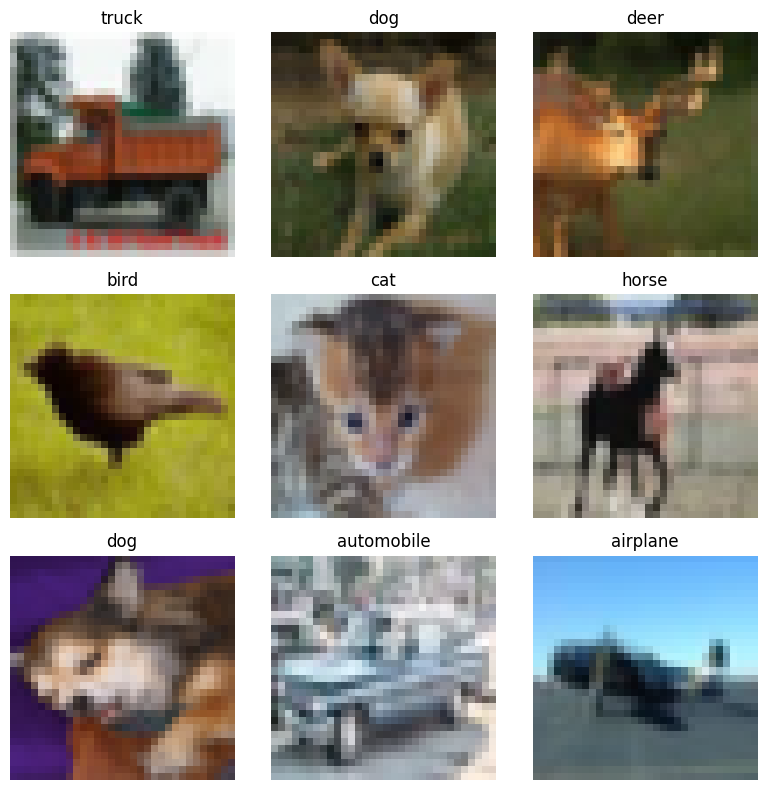

In [3]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for i in range(9):
    image = images[i].permute(1, 2, 0)
    axes.flat[i].imshow(image, interpolation="nearest")
    axes.flat[i].set_title(train_dataset.classes[labels[i].item()])
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()


In [4]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


Normlizing the pixel values of the image to reduce loss function, sensitivity and increase uniformity

In [5]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

normal_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

augmented_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


In [6]:
train_full_A = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=normal_transform
)

train_full_B = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=augmented_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=normal_transform
)

indices = torch.randperm(
    len(train_full_A), generator=torch.Generator().manual_seed(42)
).tolist()
train_indices = indices[:45000]
val_indices = indices[45000:]

train_dataset_A = Subset(train_full_A, train_indices)
train_dataset_B = Subset(train_full_B, train_indices)
validation_dataset = Subset(train_full_A, val_indices)

more_indices = torch.randperm(
    len(train_full_A), generator=torch.Generator().manual_seed(4)
).tolist()
more_train_indices = more_indices[:45000]
more_val_indices = more_indices[45000:]

more_train_dataset_A = Subset(train_full_A, more_train_indices)
more_train_dataset_B = Subset(train_full_B, more_train_indices)
more_validation_dataset = Subset(train_full_A, more_val_indices)


In [7]:
train_loader_A = DataLoader(train_dataset_A, batch_size=BATCH_SIZE, shuffle=True)
train_loader_B = DataLoader(train_dataset_B, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

more_train_loader_A = DataLoader(more_train_dataset_A, batch_size=BATCH_SIZE, shuffle=True)
more_train_loader_B = DataLoader(more_train_dataset_B, batch_size=BATCH_SIZE, shuffle=True)
more_val_loader = DataLoader(more_validation_dataset, batch_size=BATCH_SIZE, shuffle=False)


In [8]:
class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


In [9]:
class MoreImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.10),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.35),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


In [10]:
TRAIN_MODELS = False
LOCAL_DIR = Path("checkpoints")
DRIVE_DIR = Path("/content/drive/MyDrive/ACM_Trailcam")

if not (LOCAL_DIR / "run_A_best.pt").exists() and drive is not None:
    drive.mount("/content/drive")

SAVE_DIR = LOCAL_DIR if (LOCAL_DIR / "run_A_best.pt").exists() else DRIVE_DIR
HISTORY_DIR = Path("histories") if Path("histories/run_A_history.json").exists() else SAVE_DIR
MORE_DIR = LOCAL_DIR if (LOCAL_DIR / "more_improved_A_best.pt").exists() else DRIVE_DIR / "More_Improved_CNN"
MORE_HISTORY_DIR = Path("histories") if Path("histories/more_improved_A_history.json").exists() else MORE_DIR
OUTPUT_DIR = Path.cwd() if SAVE_DIR == LOCAL_DIR else DRIVE_DIR
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if TRAIN_MODELS:
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    MORE_DIR.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive


In [11]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


In [12]:
def train_cnn(model, train_loader, val_loader, epochs, run_name):

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    checkpoint_path = SAVE_DIR / f"{run_name}_last.pt"
    best_path = SAVE_DIR / f"{run_name}_best.pt"
    history_path = SAVE_DIR / f"{run_name}_history.json"

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1.0
    start_epoch = 0

    if checkpoint_path.exists():
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])

        history = checkpoint["history"]
        best_val_accuracy = checkpoint["best_val_accuracy"]
        start_epoch = checkpoint["epoch"]

        torch.set_rng_state(checkpoint["cpu_rng_state"])

        if device.type == "cuda" and checkpoint["cuda_rng_state"] is not None:
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_state"])

        print(f"{run_name} {start_epoch + 1}")

    for epoch in range(start_epoch, epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        val_loss, val_accuracy = evaluate(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            torch.save(model.state_dict(), best_path)

        checkpoint = {
            "epoch": epoch + 1,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
            "best_val_accuracy": best_val_accuracy,
            "cpu_rng_state": torch.get_rng_state(),
            "cuda_rng_state": (
                torch.cuda.get_rng_state_all()
                if device.type == "cuda" else None
            )
        }

        torch.save(checkpoint, checkpoint_path)

        with open(history_path, "w") as f:
            json.dump(history, f, indent=2)

        print(
            f"{run_name} {epoch + 1}/{epochs} | "
            f"train loss {train_loss:.4f} | "
            f"train acc {train_accuracy:.2f}% | "
            f"val loss {val_loss:.4f} | "
            f"val acc {val_accuracy:.2f}%",
            flush=True
        )


    print(f"{run_name} done")

    return history


In [13]:
if TRAIN_MODELS:
    torch.manual_seed(42)
    model_A = SimpleCNN().to(device)
    history_A = train_cnn(model_A, train_loader_A, val_loader, 30, "run_A")


In [14]:
if TRAIN_MODELS:
    torch.manual_seed(42)
    model_B = SimpleCNN().to(device)
    history_B = train_cnn(model_B, train_loader_B, val_loader, 30, "run_B")


In [15]:
if TRAIN_MODELS:
    torch.manual_seed(42)
    model_C = ImprovedCNN().to(device)
    history_C = train_cnn(model_C, train_loader_A, val_loader, 30, "run_C")


In [16]:
if TRAIN_MODELS:
    torch.manual_seed(42)
    model_D = ImprovedCNN().to(device)
    history_D = train_cnn(model_D, train_loader_B, val_loader, 30, "run_D")

In [17]:
def train_more_improved(model, train_loader, val_loader, epochs, run_name):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=1e-5
    )
    checkpoint_path = MORE_DIR / f"more_improved_{run_name}_last.pt"
    best_path = MORE_DIR / f"more_improved_{run_name}_best.pt"
    history_path = MORE_DIR / f"more_improved_{run_name}_history.json"
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "lr": []
    }
    best_val_accuracy = -1.0
    start_epoch = 0

    if checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])
        history = checkpoint["history"]
        best_val_accuracy = checkpoint["best_val_accuracy"]
        start_epoch = checkpoint["epoch"]
        torch.set_rng_state(checkpoint["cpu_rng_state"])
        if device.type == "cuda" and checkpoint["cuda_rng_state"] is not None:
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_state"])

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        lr = optimizer.param_groups[0]["lr"]

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total
        val_loss, val_accuracy = evaluate(model, val_loader, criterion)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["lr"].append(lr)

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            torch.save(model.state_dict(), best_path)
        scheduler.step()
        checkpoint = {
            "epoch": epoch + 1,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "history": history,
            "best_val_accuracy": best_val_accuracy,
            "cpu_rng_state": torch.get_rng_state(),
            "cuda_rng_state": (
                torch.cuda.get_rng_state_all() if device.type == "cuda" else None
            )
        }
        torch.save(checkpoint, checkpoint_path)
        with open(history_path, "w") as f:
            json.dump(history, f, indent=2)
        print(f"more_{run_name} {epoch+1}/{epochs} train {train_accuracy:.2f}% val {val_accuracy:.2f}%")
    return history


In [18]:
if TRAIN_MODELS:
    for run, loader in [("A", more_train_loader_A), ("B", more_train_loader_B)]:
        torch.manual_seed(4)
        model = MoreImprovedCNN().to(device)
        train_more_improved(model, loader, more_val_loader, 30, run)


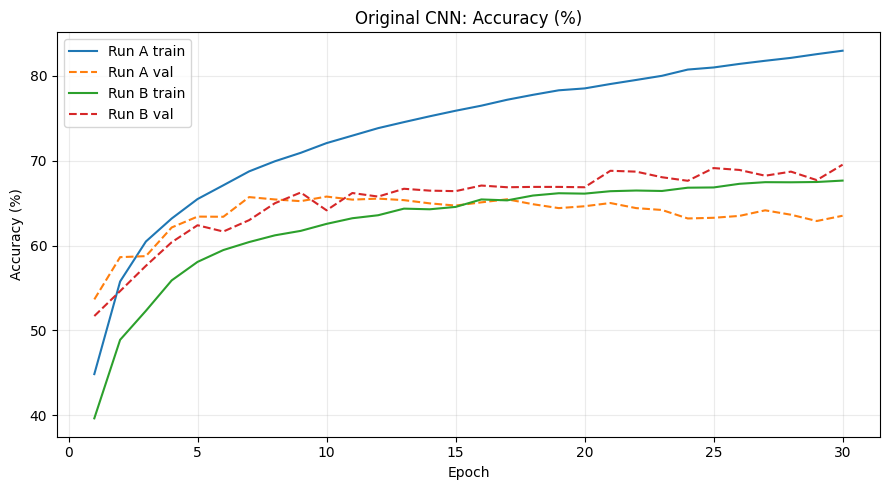

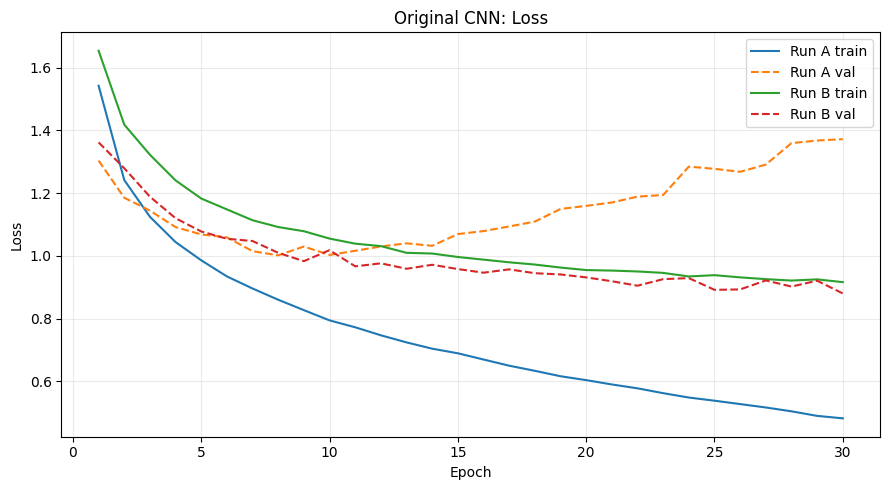

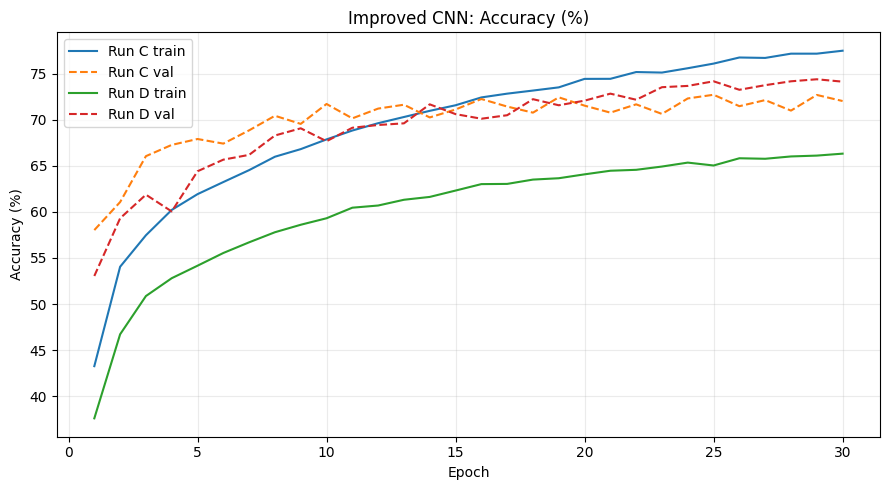

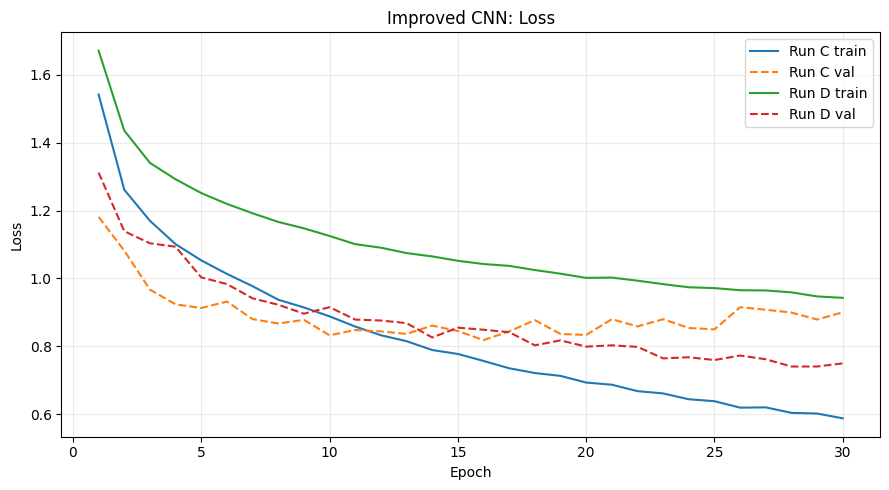

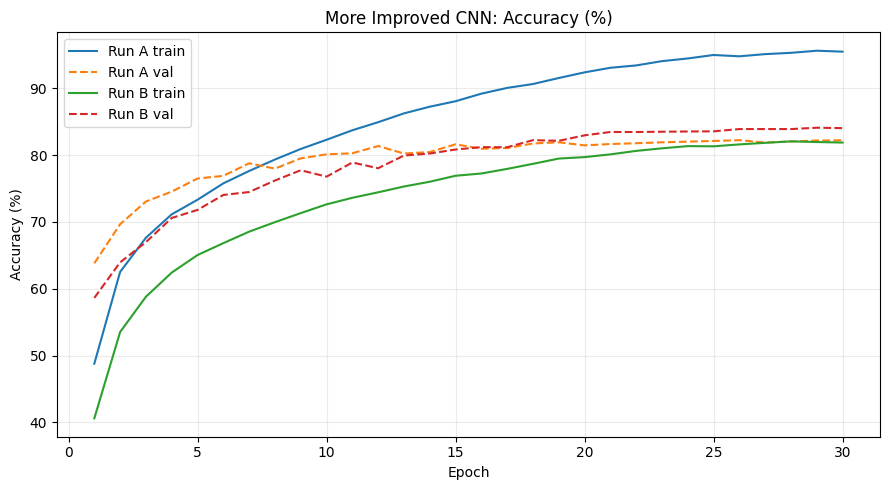

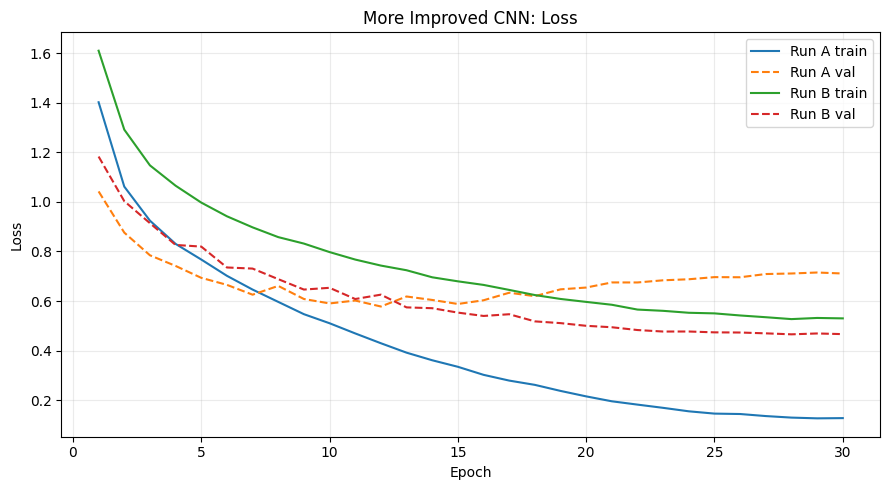

In [19]:
history = {}
for run in "ABCD":
    with open(HISTORY_DIR / f"run_{run}_history.json") as f:
        history[run] = json.load(f)

more_history = {}
for run in "AB":
    with open(MORE_HISTORY_DIR / f"more_improved_{run}_history.json") as f:
        more_history[run] = json.load(f)

for name, curves in [
    ("original", {run: history[run] for run in "AB"}),
    ("improved", {run: history[run] for run in "CD"}),
    ("more_improved", {run: more_history[run] for run in "AB"})
]:
    for metric, label in [("accuracy", "Accuracy (%)"), ("loss", "Loss")]:
        fig, ax = plt.subplots(figsize=(9, 5))
        for run, values in curves.items():
            epochs = range(1, len(values[f"train_{metric}"]) + 1)
            ax.plot(epochs, values[f"train_{metric}"], label=f"Run {run} train")
            ax.plot(epochs, values[f"val_{metric}"], linestyle="--", label=f"Run {run} val")
        ax.set(xlabel="Epoch", ylabel=label, title=f"{name.replace('_', ' ').title()} CNN: {label}")
        ax.legend()
        ax.grid(alpha=0.25)
        fig.tight_layout()
        fig.savefig(FIGURE_DIR / f"{name}_{metric}.png", dpi=180)
        plt.show()


In [20]:
criterion = nn.CrossEntropyLoss()
models = {}
test_results = {}

for run in "ABCD":
    model_class = SimpleCNN if run in "AB" else ImprovedCNN
    model = model_class().to(device)
    model.load_state_dict(torch.load(SAVE_DIR / f"run_{run}_best.pt", map_location=device, weights_only=True))
    test_loss, test_acc = evaluate(model, test_loader, criterion)
    models[run] = model
    test_results[run] = {"loss": test_loss, "accuracy": test_acc}
    print(f"{run}: {test_acc:.2f}%")

for run in "AB":
    model = MoreImprovedCNN().to(device)
    path = MORE_DIR / f"more_improved_{run}_best.pt"
    model.load_state_dict(torch.load(path, map_location=device, weights_only=True))
    test_loss, test_acc = evaluate(model, test_loader, criterion)
    models[f"more_{run}"] = model
    test_results[f"more_{run}"] = {"loss": test_loss, "accuracy": test_acc}
    print(f"more_{run}: {test_acc:.2f}%")


A: 66.09%
B: 70.07%
C: 73.33%
D: 74.96%
more_A: 82.14%
more_B: 83.87%


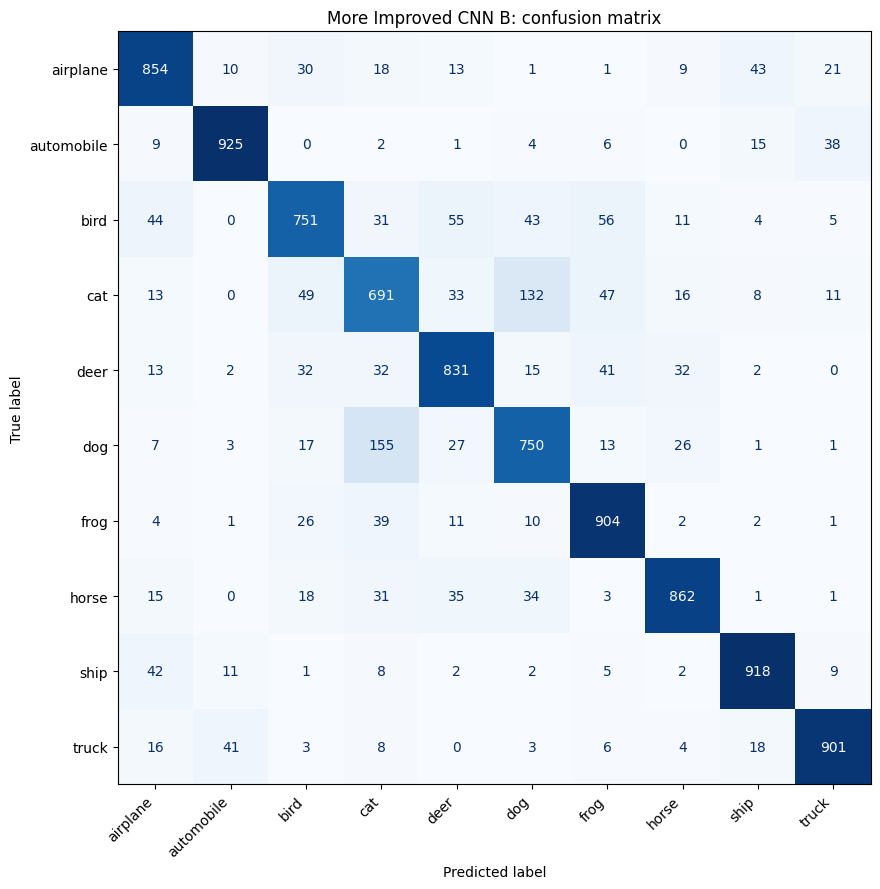

pair: cat / dog (287)
cat -> dog: 132
dog -> cat: 155


In [21]:
true_labels = []
pred_labels = []
wrong_images = []

best_model = models["more_B"]
best_model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        outputs = best_model(images.to(device))
        preds = outputs.argmax(dim=1).cpu()
        true_labels.extend(labels.tolist())
        pred_labels.extend(preds.tolist())
        if len(wrong_images) < 9:
            for image, actual, pred in zip(images, labels, preds):
                if actual.item() != pred.item():
                    wrong_images.append((image.clone(), actual.item(), pred.item()))
                    if len(wrong_images) == 9:
                        break

classes = test_dataset.classes
matrix = confusion_matrix(true_labels, pred_labels, labels=range(10))
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_title("More Improved CNN B: confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "confusion_matrix_more_improved_B.png", dpi=180)
plt.show()

pair_counts = matrix + matrix.T
np.fill_diagonal(pair_counts, 0)
i, j = np.unravel_index(pair_counts.argmax(), pair_counts.shape)
wrong_by_class = matrix.sum(axis=1) - np.diag(matrix)
most_wrong = np.argsort(wrong_by_class)[::-1][:2]

print(f"pair: {classes[i]} / {classes[j]} ({pair_counts[i, j]})")
print(f"{classes[i]} -> {classes[j]}: {matrix[i, j]}")
print(f"{classes[j]} -> {classes[i]}: {matrix[j, i]}")


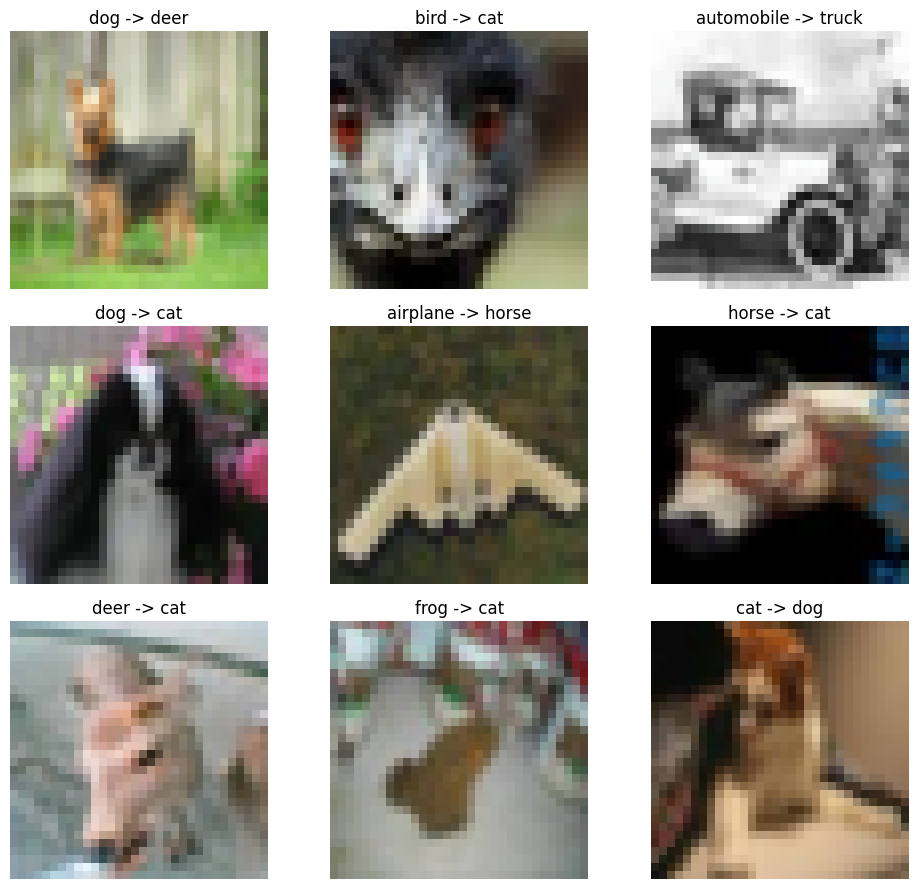

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for ax, (image, actual, pred) in zip(axes.flat, wrong_images):
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image * np.array(std) + np.array(mean), 0, 1)
    ax.imshow(image, interpolation="nearest")
    ax.set_title(f"{classes[actual]} -> {classes[pred]}")
    ax.axis("off")

plt.tight_layout()
fig.savefig(FIGURE_DIR / "misclassified_more_improved_B.png", dpi=180)
plt.show()


In [23]:
results = {
    "test_accuracy": {run: round(item["accuracy"], 2) for run, item in test_results.items()},
    "most_confused_pair": [classes[i], classes[j]],
    "pair_total": int(pair_counts[i, j]),
    "confused_directions": {
        f"{classes[i]} -> {classes[j]}": int(matrix[i, j]),
        f"{classes[j]} -> {classes[i]}": int(matrix[j, i])
    },
    "most_errors": {classes[int(k)]: int(wrong_by_class[k]) for k in most_wrong}
}

with open(OUTPUT_DIR / "results.json", "w") as f:
    json.dump(results, f, indent=2)

report = (
    f"Original CNN: {test_results['A']['accuracy']:.2f}% without augmentation and "
    f"{test_results['B']['accuracy']:.2f}% with augmentation. "
    f"Improved CNN: {test_results['C']['accuracy']:.2f}% without augmentation and "
    f"{test_results['D']['accuracy']:.2f}% with augmentation. "
    f"More Improved CNN: {test_results['more_A']['accuracy']:.2f}% without augmentation and "
    f"{test_results['more_B']['accuracy']:.2f}% with augmentation. "
    f"For the More Improved CNN B model, the most confused pair was {classes[i]} and {classes[j]} "
    f"with {pair_counts[i, j]} total mistakes in both directions: "
    f"{matrix[i, j]} {classes[i]} to {classes[j]} and "
    f"{matrix[j, i]} {classes[j]} to {classes[i]}."
)

(OUTPUT_DIR / "field_report.md").write_text(report, encoding="utf-8")
readme_file = OUTPUT_DIR / ("README.md" if SAVE_DIR == LOCAL_DIR else "README_Updated.md")
if readme_file.exists():
    readme = readme_file.read_text(encoding="utf-8")
    if "**Field report:** " in readme and "\n\n## Files" in readme:
        start = readme.index("**Field report:** ")
        end = readme.index("\n\n## Files", start)
        readme_file.write_text(readme[:start] + "**Field report:** " + report + readme[end:], encoding="utf-8")

print("report: field_report.md")


report: field_report.md
